# AMLSim EDA and feasibility checks

Goal: decide whether AMLSim output can serve as the main dataset (D1) of EarlyMule-TG, and understand what the generated data looks like.

Each feasibility question is answered with a number, and the summary table at the end collects them:

| Check | Question |
|---|---|
| Pipeline | Does AMLSim run end to end and produce consistent files? |
| Temporal ground truth | Can each mule's start, first inflow/outflow and completion be derived from the output? |
| Time resolution | How long is one step, and do laundering chains span several steps? |
| Prior history | Do mule accounts have normal activity before their first illicit transaction? |
| Static leakage | Can static account attributes alone separate mules from normal accounts? |
| Difficulty | Is the problem neither trivial nor hopeless for simple features? |

Data: default `conf.json` with `paramFiles/1K` (simulation `sample`) and `paramFiles/10K` (simulation `10K`), AMLSim commit `7338a4b`, seed 0.
Main analysis uses **10K**; 1K is compared at the end.

In [1]:
# Setup: imports, display options, paths and the shared loader used by every section
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score, average_precision_score
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.ensemble import HistGradientBoostingClassifier

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)
plt.rcParams["figure.figsize"] = (9, 3.2)

AMLSIM = Path("..") / "AMLSim"                        # run the notebook from notebooks/
BASE_DATE = pd.Timestamp("2017-01-01", tz="UTC")       # base_date in AMLSim conf.json = step 0


def load(sim):
    """Load one AMLSim run and add a `step` column (days since BASE_DATE) to the transaction tables.

    Args:
        sim: simulation name, i.e. the folder under outputs/ and tmp/ ("sample" for 1K, "10K").
    Returns:
        dict of DataFrames: final outputs from outputs/<sim>/ plus the generator's
        alert_members.csv from tmp/<sim>/, which holds the planned alert windows and main accounts.
    """
    out, tmp = AMLSIM / "outputs" / sim, AMLSIM / "tmp" / sim
    # 1. Read final outputs and the generator's planned alert membership
    d = {
        "accounts": pd.read_csv(out / "accounts.csv"),
        "tx": pd.read_csv(out / "transactions.csv"),
        "alert_accounts": pd.read_csv(out / "alert_accounts.csv"),
        "alert_tx": pd.read_csv(out / "alert_transactions.csv"),
        "sar_accounts": pd.read_csv(out / "sar_accounts.csv"),
        "tx_count": pd.read_csv(out / "tx_count.csv"),
        "alert_members": pd.read_csv(tmp / "alert_members.csv"),
    }
    # 2. Convert timestamps back to integer steps; one step is one day (checked in section 3)
    for k in ("tx", "alert_tx"):
        t = pd.to_datetime(d[k]["tran_timestamp"])
        d[k]["step"] = (t - BASE_DATE).dt.days
    return d


# Main analysis runs on 10K; short aliases keep the cells below readable
SIM = "10K"
D = load(SIM)
acc, tx, aa, at, am = D["accounts"], D["tx"], D["alert_accounts"], D["alert_tx"], D["alert_members"]

## 1. Files and schema

In [2]:
# List every output CSV with its row count and first columns
out = AMLSIM / "outputs" / SIM
rows = []
for f in sorted(out.glob("*.csv")):
    df = pd.read_csv(f, nrows=0)                               # header only
    n = sum(1 for _ in open(f, encoding="utf-8")) - 1          # count lines without loading the file; minus header
    rows.append({"file": f.name, "rows": n, "columns": len(df.columns), "first columns": ", ".join(df.columns[:6])})
pd.DataFrame(rows)

,file,rows,columns,first columns
0,accountMapping.csv,12043,6,"cust_acct_mapping_id, acct_id, cust_id, cust_a..."
1,accounts.csv,12043,24,"acct_id, dsply_nm, type, acct_stat, acct_rptng..."
2,alert_accounts.csv,742,10,"alert_id, alert_type, acct_id, acct_name, is_s..."
3,alert_transactions.csv,671,9,"alert_id, alert_type, is_sar, tran_id, orig_ac..."
4,cash_tx.csv,0,8,"tran_id, orig_acct, bene_acct, tx_type, base_a..."
5,individuals-bulkload.csv,6089,31,"birthPlaceCountry, countryofResidency, deathTi..."
6,organizations-bulkload.csv,5954,32,"birthPlaceCountry, countryOfIncorporation, cou..."
7,resolvedentities.csv,0,8,"entityrefid, entityreference, partyid1, partyi..."
8,sar_accounts.csv,737,7,"ALERT_ID, ACCOUNT_ID, CUSTOMER_ID, EVENT_DATE,..."
9,transactions.csv,197905,8,"tran_id, orig_acct, bene_acct, tx_type, base_a..."


## 2. Overview

In [3]:
# Headline counts. "Active" = account appears as sender or receiver at least once
active = set(tx.orig_acct) | set(tx.bene_acct)
sar_accts = set(aa.acct_id)                                  # planned alert members, used as the SAR account label
overview = pd.Series({
    "accounts": len(acc),
    "accounts with >= 1 transaction": len(active),
    "transactions": len(tx),
    "SAR transactions": int(tx.is_sar.sum()),
    "SAR transaction rate (%)": round(100 * tx.is_sar.mean(), 3),
    "alerts": aa.alert_id.nunique(),
    "alert (SAR) accounts": len(sar_accts),
    "SAR account rate among active (%)": round(100 * len(sar_accts) / len(active), 2),   # denominator: active accounts only
    "accounts in more than one alert": int((aa.acct_id.value_counts() > 1).sum()),
    "transaction types": ", ".join(tx.tx_type.unique()),
})
overview.to_frame("value")

,value
accounts,12043
accounts with >= 1 transaction,4672
transactions,197905
SAR transactions,671
SAR transaction rate (%),0.339
alerts,100
alert (SAR) accounts,742
SAR account rate among active (%),15.88
accounts in more than one alert,0
transaction types,TRANSFER


Note: many accounts never transact. They appear in the normal-model list (`tmp/<sim>/normal_models.csv`) but their models never fire.
They are isolated nodes and should be dropped or kept consistently in every split.

## 3. Time resolution

In [4]:
# Is there any time-of-day information? If every timestamp is midnight, the finest unit is one day
ts = pd.to_datetime(tx.tran_timestamp)
time_check = pd.Series({
    "distinct timestamps": ts.nunique(),
    "distinct steps": tx.step.nunique(),
    "first timestamp": ts.min(),
    "last timestamp": ts.max(),
    "timestamps with a non-midnight time": int((ts.dt.floor("D") != ts).sum()),
})
time_check.to_frame("value")

,value
distinct timestamps,720
distinct steps,720
first timestamp,2017-01-01 00:00:00+00:00
last timestamp,2018-12-21 00:00:00+00:00
timestamps with a non-midnight time,0


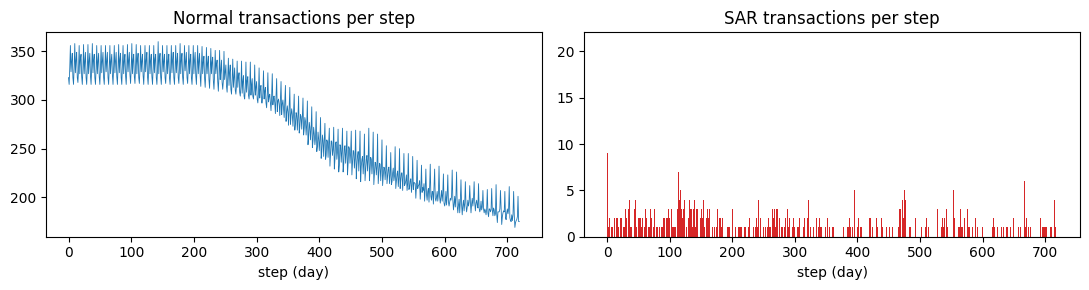

In [5]:
# Daily volume of normal vs SAR transactions, from AMLSim's own per-step counter
tc = D["tx_count"]
fig, ax = plt.subplots(1, 2, figsize=(11, 3))
ax[0].plot(tc.step, tc.normal, lw=0.6); ax[0].set(title="Normal transactions per step", xlabel="step (day)")
ax[1].bar(tc.step, tc.SAR, width=1.0, color="C3"); ax[1].set(title="SAR transactions per step", xlabel="step (day)")
plt.tight_layout()

One step is one calendar day and every timestamp is midnight, so there is **no intra-day resolution**.
Hour-based windows (1h, 24h) collapse to "same day"; windows must be expressed in days (for example 1d / 7d / 30d).

## 4. Alerts and typologies

In [6]:
# Planned window (generator) vs actual window (logged SAR transactions) for every alert
# 1. Planned: typology, member count and start/end step from tmp/alert_members.csv
gen = am.groupby("alertID").agg(typology=("reason", "first"), members=("accountID", "size"),
                                gen_start=("startStep", "first"), gen_end=("endStep", "first"))
# 2. Actual: first/last step and amount range of the alert's logged transactions
real = at.groupby("alert_id").agg(n_tx=("tran_id", "size"), first_step=("step", "min"), last_step=("step", "max"),
                                  amount_min=("base_amt", "min"), amount_max=("base_amt", "max"))
alerts = gen.join(real)
# 3. Span = last - first step, in days; compare planned vs actual per typology
alerts["gen_span"] = alerts.gen_end - alerts.gen_start
alerts["real_span"] = alerts.last_step - alerts.first_step
alerts.groupby("typology").agg(alerts=("members", "size"), members_mean=("members", "mean"), n_tx_mean=("n_tx", "mean"),
                               gen_span_median=("gen_span", "median"), real_span_median=("real_span", "median"),
                               real_span_max=("real_span", "max"), first_step_median=("first_step", "median")).round(1)

,alerts,members_mean,n_tx_mean,gen_span_median,real_span_median,real_span_max,first_step_median
typology,,,,,,,
cycle,40,7.4,7.3,12.0,12.0,19,428.0
fan_in,30,7.7,6.6,11.5,363.0,616,0.0
fan_out,30,7.1,6.0,14.5,195.0,543,36.0


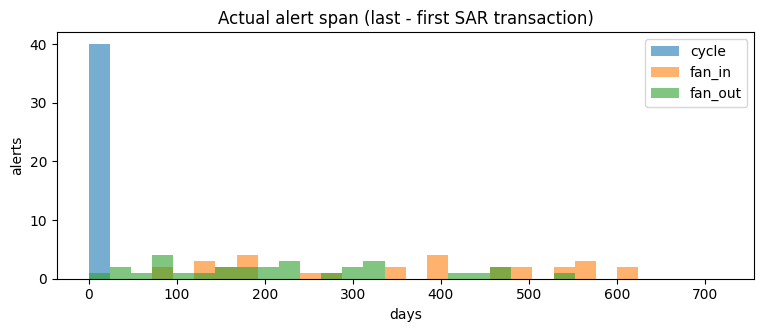

In [7]:
# Distribution of actual alert spans per typology, over the full 720-day simulation
fig, ax = plt.subplots(figsize=(9, 3.2))
for i, (t, g) in enumerate(alerts.groupby("typology")):
    ax.hist(g.real_span, bins=30, range=(0, 720), alpha=0.6, label=t)
ax.set(title="Actual alert span (last - first SAR transaction)", xlabel="days", ylabel="alerts"); ax.legend()

The generator gives every alert a 5-20 day window (`gen_span`), but the Java simulator does not keep it:

- **cycle** keeps its length but is moved to a random position;
- **fan_in / fan_out** are stretched over hundreds of days. `FanInTypology.java:49` and `FanOutTypology.java:47`
  overwrite `startStep` with a random number in `[0, interval)` instead of an offset, so the first transaction falls near step 0.

Any temporal ground truth must therefore be read from the actual transactions, never from the generator parameters.

In [8]:
# One example edge list per typology, sorted by day, to eyeball who sends to whom and when
for t in ["fan_in", "fan_out", "cycle"]:
    aid = alerts[alerts.typology == t].index[0]
    main = am[(am.alertID == aid) & (am.isMain)].accountID.tolist()
    print(f"{t} alert {aid}, main account {main}")
    print(at[at.alert_id == aid][["step", "orig_acct", "bene_acct", "base_amt"]].sort_values("step").to_string(index=False), "\n")

fan_in alert 0, main account [376]
 step  orig_acct  bene_acct  base_amt
    0       4650        376    911.81
   57      10638        376    491.04
  114       2513        376    625.47
  171       9014        376    307.45
  228       5639        376    246.97
  285       8644        376    794.11
  342       6363        376    379.23 

fan_out alert 30, main account [136]
 step  orig_acct  bene_acct  base_amt
   52        136       6411    335.26
   61        136        875    167.31
  124        136       1518    339.00
  155        136       1517    620.10
  168        136       1460    233.88
  221        136       3975    278.97
  233        136       4392    958.84
  382        136       9996    266.09 

cycle alert 60, main account [325]
 step  orig_acct  bene_acct  base_amt
  419        325       8695    653.13
  419        429       9448    890.86
  423       9448       3820    110.04
  424       3820       7127    216.71
  428       7127        325    762.64
  432       869

## 5. Roles inside an alert

AMLSim flags **every member** of an alert as SAR, including the external sources of a fan-in and the destinations of a fan-out.
A mule in the thesis sense is the account that receives and forwards money, so roles are derived from the direction of illicit transactions.

In [9]:
# Derive a role for each alert member from the direction of its illicit transactions
# 1. Illicit inflow / outflow count and first/last day per account
inn = at.groupby("bene_acct").agg(ill_in=("tran_id", "size"), first_in=("step", "min"), last_in=("step", "max"))
outn = at.groupby("orig_acct").agg(ill_out=("tran_id", "size"), first_out=("step", "min"), last_out=("step", "max"))
# 2. One row per alert member; members with no illicit event keep NaN days and count 0
#    (indexing by acct_id is safe only because no account is in two alerts, see section 2)
gt = aa[["acct_id", "alert_id", "alert_type"]].set_index("acct_id").join(inn).join(outn)
gt[["ill_in", "ill_out"]] = gt[["ill_in", "ill_out"]].fillna(0).astype(int)
gt["is_main"] = gt.index.isin(am[am.isMain].accountID)


def role(r):
    """Provisional structural role of one alert member (audit only, not the approved mule label).

    Counts events, not distinct counterparties. Rules are checked in order, so an account
    with both inflow and outflow is always a relay.
    """
    if r.ill_in > 0 and r.ill_out > 0:
        return "relay (in and out)"
    if r.ill_in > 1:
        return "collector (many in, no out)"
    if r.ill_out > 1:
        return "disperser (many out, no in)"
    if r.ill_out == 1:
        return "source (1 out)"
    if r.ill_in == 1:
        return "destination (1 in)"
    return "no illicit tx"


# 3. Role by typology and main/non-main member
gt["role"] = gt.apply(role, axis=1)
pd.crosstab([gt.alert_type, gt.is_main], gt.role)

role                collector (many in, no out)  destination (1 in)  disperser (many out, no in)  no illicit tx  relay (in and out)  source (1 out)
alert_type is_main                                                                                                                                 
cycle      False                              0                   4                            0              0                 249               5
           True                               0                   2                            0              1                  36               1
fan_in     False                              0                   0                            0              1                   0             199
           True                              30                   0                            0              0                   0               0
fan_out    False                              0                 181                            0              3                   0               0
           True                               0                   0                           30              0                   0               0

- In **fan_in** only the main account is a collector; the other members are sources that send once.
- In **fan_out** only the main account is a disperser; the others are destinations that receive once.
- In **cycle** most members both receive and forward: they are the relays. A few cycle members have no logged illicit event in one direction, so they are not counted as relays.

So only about one account per fan alert, plus most cycle members, behaves like a mule. The others are counterparties.
These roles are a structural rule used for this audit, not the final mule label.
Using `is_sar` from AMLSim as the mule label would mix mules with their counterparties.

## 6. Temporal ground truth

In [10]:
# Candidate milestones per account and how many accounts have them
# start = first illicit event in either direction; completion = last illicit event (proxy, no cash-out data)
# min/max skip NaN, so a one-directional account (collector, disperser) still gets both milestones
gt["mule_start"] = gt[["first_in", "first_out"]].min(axis=1)
gt["completion"] = gt[["last_in", "last_out"]].max(axis=1)
mule_like =gt.role.isin(["relay (in and out)", "collector (many in, no out)", "disperser (many out, no in)"])
cov = pd.Series({
    "alert accounts": len(gt),
    "with >= 1 illicit transaction": int((gt.role != "no illicit tx").sum()),
    "mule-like (relay / collector / disperser)": int(mule_like.sum()),
    "mule-like with start and completion": int(gt[mule_like][["mule_start", "completion"]].notna().all(axis=1).sum()),
    "relays with first inflow and first outflow": int(gt[gt.role.str.startswith("relay")][["first_in", "first_out"]].notna().all(axis=1).sum()),
    "relays total": int(gt.role.str.startswith("relay").sum()),
})
cov.to_frame("count")

,count
alert accounts,742
with >= 1 illicit transaction,737
mule-like (relay / collector / disperser),345
mule-like with start and completion,345
relays with first inflow and first outflow,285
relays total,285


In [11]:
# Holding time of relays: days from first inflow to first outflow (negative = forwards before receiving)
relays = gt[gt.role.str.startswith("relay")].copy()
relays["hold_days"] = relays.first_out - relays.first_in
relays.hold_days.describe().round(1).to_frame("first outflow - first inflow (days), relays")

,"first outflow - first inflow (days), relays"
count,285.0
mean,-0.0
std,7.4
min,-17.0
25%,-5.0
50%,-1.0
75%,4.0
max,19.0


In [12]:
# Causal order: does a relay receive money before it forwards it?
# Main accounts are left out, as in the audit notes, so the check covers only members that pass money on.
# Same-day events count as "not before": with day resolution their order is unknown.
cyc =gt[(gt.alert_type == "cycle") & gt.role.str.startswith("relay") & ~gt.is_main]
pd.Series({
    "cycle relays (not the main account)": len(cyc),
    "forward before they first receive": int((cyc.first_out < cyc.first_in).sum()),
    "share (%)": round(100 * (cyc.first_out < cyc.first_in).mean(), 1),
    "schedule_id used by all alerts": ", ".join(map(str, am.scheduleID.unique())),
}).to_frame("value")

,value
cycle relays (not the main account),249
forward before they first receive,112
share (%),45.0
schedule_id used by all alerts,2


With `schedule_id = 2` the cycle uses `UNORDERED` scheduling (`AMLTypology.java:38`): transaction steps are random and not sorted,
so many relays send money before they have received it. For mule semantics (inflow, then outflow) cycles should use
`schedule_id = 1` (`RANDOM_INTERVAL`, sorted steps). Fan typologies interpret the same id differently (`FanInTypology.java:24`).

What can be read from `alert_transactions.csv`:

- **Start** (first illicit event) and a **completion proxy** (last illicit event): available for every mule-like account.
- **First inflow and first outflow**: available together only for relays. Collectors only receive and dispersers only send,
  so one of the two milestones does not exist for them; it is left empty, not set to 0.
- **Cash-out is not modelled**: `cash_tx.csv` is empty, so completion has to be defined (for example the last illicit outflow) rather than observed.

This is a first extraction for the audit. The ground-truth table used for evaluation still depends on the mule label definition
(which roles count as mules, which milestone marks completion), and that definition is not agreed yet.

## 7. Prior normal history

In [13]:
# Prior history: normal transactions strictly before each account's first illicit day
# 1. Onset per account and the normal (non-SAR) transactions
first_sar = gt.mule_start
normal_tx = tx[~tx.is_sar]
# 2. Long format: one row per (account, normal transaction side), keeping alert members only
long = pd.concat([normal_tx[["orig_acct", "step"]].rename(columns={"orig_acct": "acct"}),
                  normal_tx[["bene_acct", "step"]].rename(columns={"bene_acct": "acct"})])
long = long[long.acct.isin(gt.index)]
long["first_sar"] = long.acct.map(first_sar)
# 3. Count events with step < onset; same-day events are not "before". Accounts with none get 0,
#    so they stay in the denominator instead of disappearing
before = long[long.step < long.first_sar].groupby("acct").size()
gt["normal_before"] = gt.index.map(before).fillna(0).astype(int)
gt["normal_total"] = gt.index.map(long.groupby("acct").size()).fillna(0).astype(int)

# 4. Share of accounts reaching >= 1 / 5 / 10 prior normal events, mule-like vs counterparties
hist = pd.DataFrame({
    n: gt.groupby(mule_like.map({True: "mule-like", False: "counterparty"})).normal_before.apply(lambda s: round(100 * (s >= n).mean(), 1))
    for n in (1, 5, 10)
}).add_prefix("% with >= ").add_suffix(" normal tx before first SAR tx")
hist

,% with >= 1 normal tx before first SAR tx,% with >= 5 normal tx before first SAR tx,% with >= 10 normal tx before first SAR tx
role,,,
counterparty,23.9,15.6,14.4
mule-like,41.2,29.0,27.0


,count,min,25%,50%,75%,max
alert_type,,,,,,
cycle,285.0,0.0,0.0,0.0,12.0,987.0
fan_in,30.0,0.0,0.0,0.0,0.0,1.0
fan_out,30.0,0.0,5.0,19.0,47.5,219.0


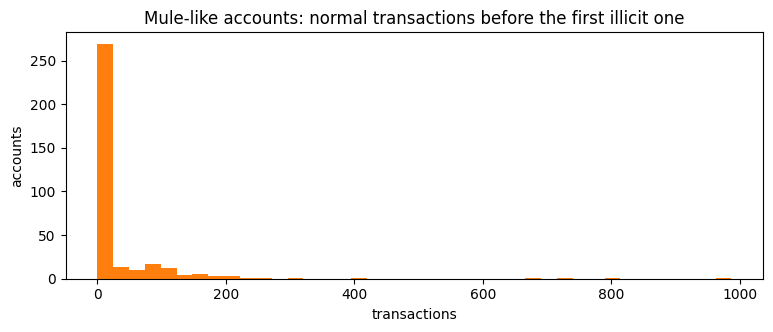

In [14]:
# Distribution of prior normal events for mule-like accounts, then the same split by typology
fig, ax = plt.subplots(figsize=(9, 3.2))
ax.hist(gt[mule_like].normal_before, bins=40, color="C1")
ax.set(title="Mule-like accounts: normal transactions before the first illicit one", xlabel="transactions", ylabel="accounts")
gt[mule_like].groupby("alert_type").normal_before.describe()[["count", "min", "25%", "50%", "75%", "max"]]

In [15]:
# Normal activity at all (whole period, not only before onset): SAR accounts vs other active accounts
# A large gap here is a shortcut a model could learn: "no normal activity" => SAR
normal_cnt =pd.concat([normal_tx.orig_acct, normal_tx.bene_acct]).value_counts()
cnt = pd.Series({a: normal_cnt.get(a, 0) for a in active})
is_sar_acct = cnt.index.isin(sar_accts)
pd.DataFrame({
    "accounts": [is_sar_acct.sum(), (~is_sar_acct).sum()],
    "% with 0 normal tx": [round(100 * (cnt[is_sar_acct] == 0).mean(), 1), round(100 * (cnt[~is_sar_acct] == 0).mean(), 1)],
    "median normal tx": [cnt[is_sar_acct].median(), cnt[~is_sar_acct].median()],
}, index=["alert accounts", "other active accounts"])

,accounts,% with 0 normal tx,median normal tx
alert accounts,741,53.4,0.0
other active accounts,3931,0.0,8.0


About half of the alert accounts never make a normal transaction: AMLSim picks alert members partly from accounts that have no normal model.
This breaks the "normal first, then mule" assumption and is also a shortcut for a model ("no normal activity" means SAR).

By typology, in this 10K run (table above):

- **fan_in** main accounts have practically no normal history before onset (at most 1 event). Their alerts start near step 0
  because of the scheduling issue, so there is no time to build any.
- **cycle** relays have a median of 0 normal events before onset; only about a quarter have 12 or more.
  Cycles start at random steps, so the cause is mainly member selection, not timing: of the 173 relays with no prior
  normal event, 157 never make a normal transaction at all.
- **fan_out** main accounts are the only group where prior history is typical (median 19 events).

So the shortfall is not only a fan scheduling problem: fixing the start step alone would not make cycle relays have a normal phase.

## 8. Static leakage

In [16]:
# Which account attributes vary at all, and does prior_sar_count simply copy the label?
acc2 = acc.set_index("acct_id")
y = acc2.index.isin(sar_accts).astype(int)
varying =[c for c in acc2.columns if acc2[c].nunique() > 1]
print("columns that vary:", varying)
print("\nprior_sar_count vs label:")
print(pd.crosstab(acc2.prior_sar_count, y, rownames=["prior_sar_count"], colnames=["is alert account"]))

columns that vary: ['dsply_nm', 'prior_sar_count', 'initial_deposit', 'first_name', 'last_name', 'street_addr', 'city', 'state', 'zip', 'gender', 'birth_date', 'ssn', 'lon', 'lat']

prior_sar_count vs label:
is alert account      0    1
prior_sar_count             
False             11301    0
True                  0  742


In [17]:
# Static-leakage test: can account attributes alone (no transactions, no prior_sar_count) find SAR accounts?
# 1. Numeric encoding of the static attributes; age is measured at simulation start (2017)
static = pd.DataFrame(index=acc2.index)
static["initial_deposit"] = acc2.initial_deposit
static["age"] = 2017 - pd.to_datetime(acc2.birth_date).dt.year
static["lon"], static["lat"] = acc2.lon, acc2.lat
static["male"] = (acc2.gender == "Male").astype(int)
static["state"] = acc2.state.astype("category").cat.codes

# 2. Keep active accounts only, so "never transacts" cannot act as a hidden signal
mask = acc2.index.isin(active)
Xs, ys = static[mask], y[mask]
# 3. Out-of-fold predictions with 5-fold stratified CV; PR-AUC near the base rate means no leakage
cv = StratifiedKFold(5, shuffle=True, random_state=0)
p = cross_val_predict(HistGradientBoostingClassifier(random_state=0), Xs, ys, cv=cv, method="predict_proba")[:, 1]
pd.Series({
    "base rate (random PR-AUC)": round(ys.mean(), 4),
    "PR-AUC, static attributes only (no prior_sar_count)": round(average_precision_score(ys, p), 4),
    "ROC-AUC, static attributes only": round(roc_auc_score(ys, p), 3),
}).to_frame("value")

,value
base rate (random PR-AUC),0.1586
"PR-AUC, static attributes only (no prior_sar_count)",0.1587
"ROC-AUC, static attributes only",0.5020


Apart from `prior_sar_count`, which equals the label and must be excluded from inputs, static attributes should score close to the base rate.

## 9. Difficulty (indicative only)

Whole-period aggregates, **not point-in-time**, so they leak future information. They only show whether simple behaviour separates SAR accounts.

In [18]:
# Indicative difficulty: per-account aggregates over the WHOLE period (leaks the future, random CV)
# 1. Transaction counts, amounts and distinct counterparties, in and out
deg = pd.DataFrame({
    "out_tx": tx.groupby("orig_acct").size(),
    "in_tx": tx.groupby("bene_acct").size(),
    "out_amt": tx.groupby("orig_acct").base_amt.sum(),
    "in_amt": tx.groupby("bene_acct").base_amt.sum(),
}).fillna(0)
deg["out_cp"] = tx.groupby("orig_acct").bene_acct.nunique()
deg["in_cp"] = tx.groupby("bene_acct").orig_acct.nunique()
deg = deg.fillna(0)
yd = deg.index.isin(sar_accts).astype(int)
# 2. Single-feature ROC-AUC, then gradient boosting on all aggregates (same CV folds as section 8)
auc = {c: round(roc_auc_score(yd, deg[c]), 3) for c in deg.columns}
p = cross_val_predict(HistGradientBoostingClassifier(random_state=0), deg, yd, cv=cv, method="predict_proba")[:, 1]
pd.Series({**{f"ROC-AUC {k}": v for k, v in auc.items()},
           "base rate": round(yd.mean(), 4),
           "PR-AUC gradient boosting on aggregates": round(average_precision_score(yd, p), 4)}).to_frame("value")

,value
ROC-AUC out_tx,0.6190
ROC-AUC in_tx,0.4030
ROC-AUC out_amt,0.6110
ROC-AUC in_amt,0.4070
ROC-AUC out_cp,0.6560
ROC-AUC in_cp,0.4680
base rate,0.1586
PR-AUC gradient boosting on aggregates,0.8105


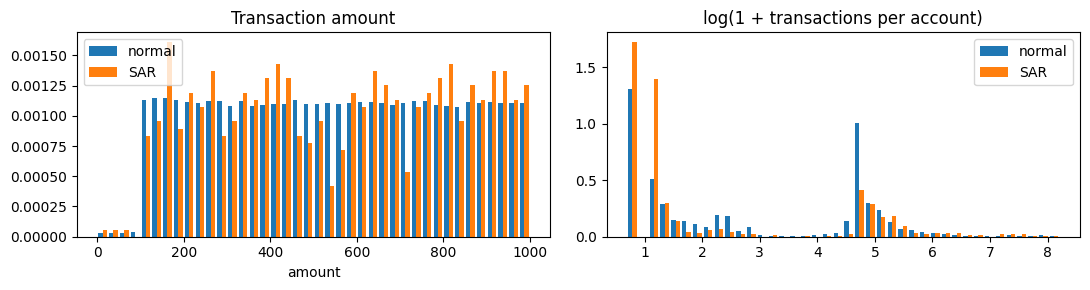

In [19]:
# Do SAR and normal differ in amount or activity level? Densities, so class sizes do not matter
fig, ax = plt.subplots(1, 2, figsize=(11, 3))
tx_n =tx[~tx.is_sar].base_amt; tx_s = tx[tx.is_sar].base_amt
ax[0].hist([tx_n, tx_s], bins=40, density=True, label=["normal", "SAR"]); ax[0].set(title="Transaction amount", xlabel="amount"); ax[0].legend()
ax[1].hist([np.log1p(deg.in_tx[yd == 0] + deg.out_tx[yd == 0]), np.log1p(deg.in_tx[yd == 1] + deg.out_tx[yd == 1])],
           bins=40, density=True, label=["normal", "SAR"]); ax[1].set(title="log(1 + transactions per account)"); ax[1].legend()
plt.tight_layout()

## 10. 1K vs 10K

In [20]:
# Same headline counts for both runs, side by side
def summary(sim):
    """Return headline counts for one AMLSim run (see load() for `sim`)."""
    d = load(sim)
    a, t, al = d["accounts"], d["tx"], d["alert_accounts"]
    act = set(t.orig_acct) | set(t.bene_acct)
    return {
        "accounts": len(a), "active accounts": len(act), "transactions": len(t),
        "alerts": al.alert_id.nunique(), "alert accounts": len(al),
        "SAR tx rate (%)": round(100 * t.is_sar.mean(), 3),
        # planned members with no logged illicit event; sar_accounts.csv lists only accounts seen in events
        "missing from sar_accounts.csv":len(set(al.acct_id) - set(d["sar_accounts"].ACCOUNT_ID)),
    }

pd.DataFrame({s: summary(s) for s in ["sample", "10K"]}).rename(columns={"sample": "1K"})

,1K,10K
accounts,1446.000,12043.000
active accounts,1354.000,4672.000
transactions,121457.000,197905.000
alerts,10.000,100.000
alert accounts,73.000,742.000
SAR tx rate (%),0.054,0.339
missing from sar_accounts.csv,1.000,5.000


## 11. Feasibility summary

In [21]:
# Collect the result of every check into one table; numbers are recomputed from the cells above
n_mule = int(mule_like.sum())
summary_rows = [
    ("Pipeline", "pass", f"{len(tx):,} transactions, {aa.alert_id.nunique()} alerts, counts match parameters"),
    ("Time resolution", "partial", "1 step = 1 day, no intra-day time; use day-based windows"),
    ("Chain length", "partial", f"cycle median {alerts[alerts.typology=='cycle'].real_span.median():.0f} days; "
                                f"fan median {alerts[alerts.typology!='cycle'].real_span.median():.0f} days (scheduling issue)"),
    ("Temporal ground truth", "partial", f"start and completion proxy for all {n_mule} mule-like accounts; first in + first out only for "
                                         f"{int(relays.first_in.notna().sum())} relays; cash-out not modelled; mule label definition not agreed yet"),
    ("Prior history", "fail (default config)", f"only {(gt[mule_like].normal_before >= 1).mean():.0%} of mule-like accounts have >= 1 normal tx before the first illicit one; "
                                               f"{(cnt[is_sar_acct] == 0).mean():.0%} of alert accounts have no normal tx at all"),
    ("Causal order", "fail for cycle", f"{(cyc.first_out < cyc.first_in).mean():.0%} of cycle relays forward before receiving (schedule_id 2 = UNORDERED)"),
    ("Static leakage", "pass after dropping prior_sar_count", "static attributes alone near base rate (section 8)"),
    ("Difficulty", "not judged yet", "whole-period aggregates give PR-AUC well above base rate but leak the future; needs point-in-time features"),
    ("Label semantics", "needs work", "is_sar marks all alert members; mule label must come from derived roles"),
]
pd.DataFrame(summary_rows, columns=["check", "result", "evidence"])

,check,result,evidence
0,Pipeline,pass,"197,905 transactions, 100 alerts, counts match..."
1,Time resolution,partial,"1 step = 1 day, no intra-day time; use day-bas..."
2,Chain length,partial,cycle median 12 days; fan median 238 days (sch...
3,Temporal ground truth,partial,start and completion proxy for all 345 mule-li...
4,Prior history,fail (default config),only 41% of mule-like accounts have >= 1 norma...
5,Causal order,fail for cycle,45% of cycle relays forward before receiving (...
6,Static leakage,pass after dropping prior_sar_count,static attributes alone near base rate (sectio...
7,Difficulty,not judged yet,whole-period aggregates give PR-AUC well above...
8,Label semantics,needs work,is_sar marks all alert members; mule label mus...
